# Текущий контроль 5–6. Метод k ближайших соседей (kNN): качество красного вина

**Задание.** С помощью метода kNN определить качество красного вина. Использовать датасет `winequality-red.csv`. Разделить набор данных на обучающий и тестовый, обучить модель на обучающем. Построить матрицу путаницы. Сделать выводы по результатам.

Файл `winequality-red.csv` должен лежать рядом с ноутбуком.

**Дополнительно к работе:** привести основные характеристики классификатора — accuracy, recall, precision, F1 — и разобраться с ROC-кривой и AUC.

**План работы**

1. Теория: как устроен kNN, что такое $k$, почему важен масштаб признаков.
2. Данные: структура, распределение оценок качества, пропуски.
3. Бинарная постановка (основная): хорошее вино — `quality ≥ 7`, остальное — не качественное. Тот же вариант разметки, что и в работе по логистической регрессии для этого вина.
4. Сравнение kNN на сырых и на стандартизованных признаках, выбор $k$ кросс-валидацией на обучающей выборке.
5. Оценка на тестовой выборке: матрица путаницы, accuracy, precision, recall, F1, ROC-кривая и AUC.
6. Дополнительно: многоклассовая постановка (оценка качества от 3 до 8) и решающие области kNN на плоскости.
7. Выводы.

## 1. Метод k ближайших соседей

**Идея.** Похожие объекты, как правило, имеют похожие ответы. Чтобы определить класс нового объекта $x$, находим в обучающей выборке $k$ самых близких к нему объектов и голосуем по их меткам.

**Расстояние.** Для объектов $x, x' \in \mathbb{R}^n$ чаще всего берут евклидово расстояние

$$\rho(x, x') = \sqrt{\sum_{j=1}^{n} \left(x_j - x'_j\right)^2}.$$

Встречается и манхэттенское расстояние $\sum_j |x_j - x'_j|$; оба случая входят в семейство расстояний Минковского. В `scikit-learn` по умолчанию используется евклидово.

**Алгоритм для объекта $x$:**

1. вычислить расстояния от $x$ до всех объектов обучающей выборки;
2. выбрать $k$ ближайших — множество $N_k(x)$;
3. предсказать класс, который среди них встречается чаще всего:

$$\hat{y}(x) = \arg\max_{c} \sum_{i \in N_k(x)} [\, y_i = c \,].$$

Доля соседей класса $c$ служит оценкой вероятности этого класса:

$$\hat{P}(y = c \mid x) = \frac{1}{k} \sum_{i \in N_k(x)} [\, y_i = c \,].$$

Эта оценка принимает всего $k+1$ значений: $0, \frac{1}{k}, \frac{2}{k}, \dots, 1$. Это пригодится, когда будем строить ROC-кривую.

**Особенности метода.**

- Явного обучения нет: метод «ленивый», он просто запоминает обучающую выборку. Вся работа происходит при предсказании, и для каждого нового объекта приходится считать расстояния до всей выборки.
- **Выбор $k$.** При малом $k$ граница между классами получается изрезанной, и модель реагирует на шум; при $k = 1$ ближайший сосед любого обучающего объекта — он сам. При большом $k$ предсказание сглаживается, а редкие классы «тонут» среди соседей из большинства; при $k$, равном размеру выборки, всегда предсказывается самый частый класс. Поэтому $k$ подбирают кросс-валидацией на обучающей выборке. В задаче с двумя классами удобно брать нечётные $k$, чтобы не было ничьих при голосовании.
- **Масштаб признаков.** Расстояние складывается из разностей по всем признакам, поэтому признак с большим числовым разбросом (например, общий диоксид серы измеряется десятками, а плотность — тысячными долями) полностью подавляет остальные. Перед kNN признаки приводят к одному масштабу, например стандартизацией:

$$z_j = \frac{x_j - \mu_j}{\sigma_j},$$

где среднее $\mu_j$ и стандартное отклонение $\sigma_j$ считаются **только по обучающей выборке**. Если посчитать их по всем данным, информация о тесте просочится в обучение. Чтобы этого не происходило, стандартизацию кладём в `Pipeline`: тогда на каждом шаге кросс-валидации она пересчитывается заново по обучающей части.

## 2. Какими метриками оцениваем качество

Положительным классом считаем «хорошее вино». По матрице путаницы получаем четыре числа: $TP$ — хорошее вино названо хорошим, $TN$ — не качественное названо не качественным, $FP$ — не качественное названо хорошим, $FN$ — хорошее названо не качественным.

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \qquad \text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN},$$

$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}.$$

- **accuracy** — доля верных ответов. При дисбалансе классов вводит в заблуждение: константа «всё не качественное» уже даёт высокую долю верных ответов.
- **precision** — из вин, названных хорошими, сколько действительно хорошие.
- **recall** — какую долю настоящих хороших вин модель нашла.
- **F1** — среднее гармоническое precision и recall; обращается в ноль, если модель не нашла ни одного хорошего вина.

## 3. Данные

Датасет Wine Quality (красное вино, UCI Machine Learning Repository). Разделитель в файле — `;`. Объект — образец вина, 11 физико-химических признаков; целевая переменная `quality` — экспертная оценка от 0 до 10 (в данных встречаются значения от 3 до 8).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 0   # один seed для разбиения на train/test и для кросс-валидации
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

In [2]:
df = pd.read_csv('winequality-red.csv', sep=';')
print(f'Размер выборки: {df.shape[0]} объектов, {df.shape[1] - 1} признаков и целевая переменная quality')
df.head()

Размер выборки: 1599 объектов, 11 признаков и целевая переменная quality


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.info()
print('Пропусков во всей таблице:', df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Пропусков во всей таблице: 0


In [4]:
df.describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
fixed acidity,8.320,1.741,4.600,15.900
volatile acidity,0.528,0.179,0.120,1.580
citric acid,0.271,0.195,0.000,1.000
residual sugar,2.539,1.410,0.900,15.500
chlorides,0.087,0.047,0.012,0.611
free sulfur dioxide,15.875,10.460,1.000,72.000
total sulfur dioxide,46.468,32.895,6.000,289.000
density,0.997,0.002,0.990,1.004
pH,3.311,0.154,2.740,4.010
sulphates,0.658,0.170,0.330,2.000


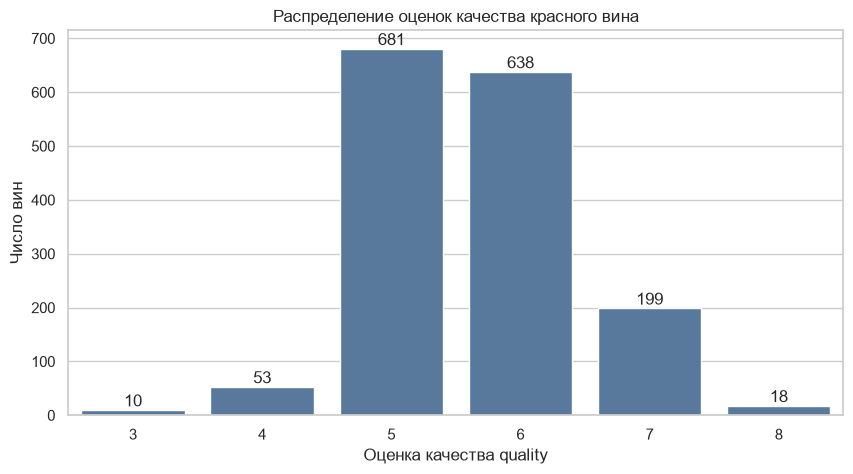

Доля каждой оценки:
quality
3    0.006
4    0.033
5    0.426
6    0.399
7    0.124
8    0.011


In [5]:
counts = df['quality'].value_counts().sort_index()

ax = sns.barplot(x=counts.index, y=counts.values, color='#4C78A8')
ax.bar_label(ax.containers[0])
ax.set_xlabel('Оценка качества quality')
ax.set_ylabel('Число вин')
ax.set_title('Распределение оценок качества красного вина')
plt.show()

print('Доля каждой оценки:')
print((counts / len(df)).round(3).to_string())

Оценки сосредоточены в середине шкалы: подавляющее большинство вин получило 5 или 6. Оценок 3 и 8 очень мало, это редкие классы — для многоклассовой постановки ниже это будет важно.

Теперь посмотрим на масштаб признаков, от которого зависит расстояние в kNN.

In [6]:
X = df.drop(columns='quality')

std = X.std().sort_values()
print('Стандартное отклонение признаков:')
print(std.round(4).to_string())
print(f'\nОтношение наибольшего разброса к наименьшему: {std.max() / std.min():.0f}')

Стандартное отклонение признаков:
density                  0.0019
chlorides                0.0471
pH                       0.1544
sulphates                0.1695
volatile acidity         0.1791
citric acid              0.1948
alcohol                  1.0657
residual sugar           1.4099
fixed acidity            1.7411
free sulfur dioxide     10.4602
total sulfur dioxide    32.8953

Отношение наибольшего разброса к наименьшему: 17430


Разброс признаков отличается на несколько порядков. Если считать евклидово расстояние по сырым значениям, в нём почти целиком будут участвовать только признаки с большим разбросом, а остальные практически ничего не изменят. Дальше сравним kNN на сырых и на стандартизованных признаках.

## 4. Бинарная постановка: хорошее вино или нет

Как и в работе по логистической регрессии для этого же вина, хорошим считаем вино с оценкой `quality ≥ 7`: класс 1 — «хорошее», класс 0 — «не качественное».

In [7]:
y = (df['quality'] >= 7).astype(int)

print(y.value_counts().rename({0: 'не качественное (0)', 1: 'хорошее (1)'}).to_string())
print(f'\nДоля хорошего вина: {y.mean():.1%}')

quality
не качественное (0)    1382
хорошее (1)             217

Доля хорошего вина: 13.6%


Классы сильно несбалансированы: хорошего вина в несколько раз меньше. Поэтому выборку делим **стратифицированно** — в обучающей и тестовой частях сохраняется одинаковая доля хорошего вина. Под тест отводим 25 % данных.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f'Обучающая выборка: {len(X_train)} объектов, доля хорошего вина {y_train.mean():.1%}')
print(f'Тестовая выборка:  {len(X_test)} объектов, доля хорошего вина {y_test.mean():.1%} '
      f'({y_test.sum()} хороших вин)')

Обучающая выборка: 1199 объектов, доля хорошего вина 13.6%
Тестовая выборка:  400 объектов, доля хорошего вина 13.5% (54 хороших вин)


**Проверка на дубликаты.** В этом датасете есть полностью повторяющиеся строки. Для kNN это важно: если у тестового объекта в обучающей выборке есть точная копия, ближайшим соседом окажется она, и оценка получится оптимистичной (насколько — показано ниже). Фолды кросс-валидации внутри обучающей выборки по дубликатам не группируются, поэтому и абсолютные значения CV-метрик могут быть слегка завышены. Посмотрим, насколько это заметно.

In [9]:
print('Полных дубликатов строк во всём датасете:', df.duplicated().sum())

train_rows = set(map(tuple, X_train.to_numpy()))
has_twin = np.array([tuple(row) in train_rows for row in X_test.to_numpy()])
print(f'Тестовых объектов, у которых в обучающей выборке есть точная копия: '
      f'{has_twin.sum()} из {len(X_test)} ({has_twin.mean():.1%})')

Полных дубликатов строк во всём датасете: 240
Тестовых объектов, у которых в обучающей выборке есть точная копия: 94 из 400 (23.5%)


Дубликаты оставляем как есть: в задании удалять их не требуется. Насколько они завышают оценку, проверим ниже, сразу после основных результатов.

### 4.1. Базовый ориентир: константная модель

Прежде чем оценивать kNN, зафиксируем, что даёт модель, которая всегда отвечает «не качественное». Любой осмысленный классификатор должен быть лучше неё по метрикам класса «хорошее».

In [10]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

print('Константная модель «всё не качественное», тест:')
print(f'  accuracy = {accuracy_score(y_test, dummy.predict(X_test)):.3f}')
print(f'  recall   = {recall_score(y_test, dummy.predict(X_test)):.3f}')
print(f'  F1       = {f1_score(y_test, dummy.predict(X_test), zero_division=0):.3f}')

Константная модель «всё не качественное», тест:
  accuracy = 0.865
  recall   = 0.000
  F1       = 0.000


Высокая accuracy у модели, которая не находит ни одного хорошего вина — наглядный пример того, почему при дисбалансе нужно смотреть на recall, precision и F1.

### 4.2. Подбор k кросс-валидацией на обучающей выборке

Тестовую выборку для подбора $k$ не используем, иначе оценка перестанет быть честной. Делим обучающую выборку на 5 фолдов (`StratifiedKFold`, с перемешиванием) и для каждого нечётного $k$ от 1 до 59 считаем средние по фолдам:

- **ROC AUC** — качество упорядочивания объектов по оценке (о нём подробно ниже);
- **F1 класса «хорошее»** при обычном решающем правиле (голосование соседей).

Всё делаем для двух вариантов: kNN на сырых признаках и kNN в `Pipeline` со `StandardScaler`.

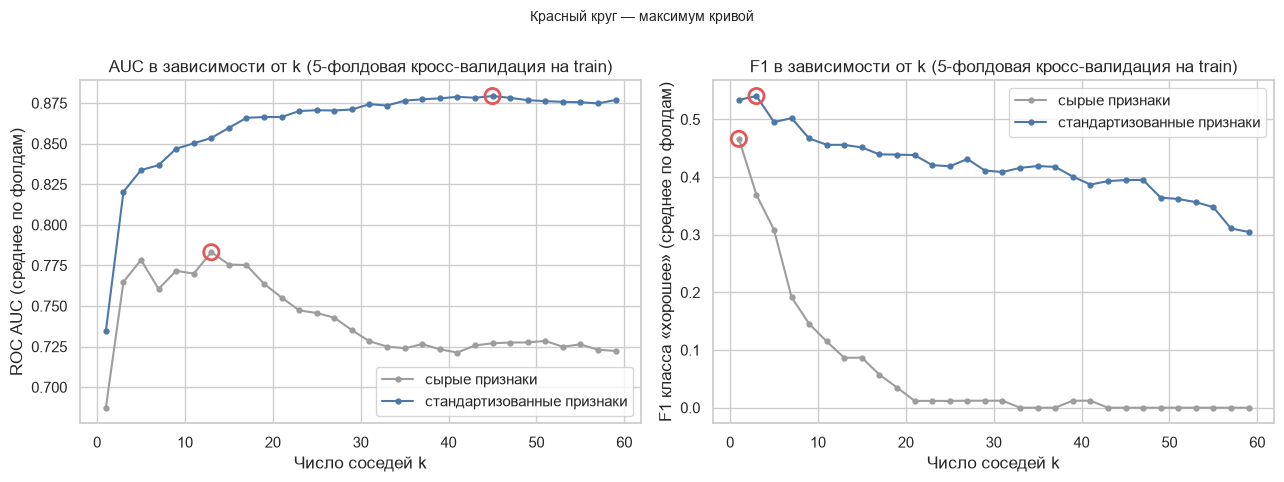

,k по F1,F1 при этом k,AUC при этом k,k по AUC,AUC при k по AUC,F1 при k по AUC
Сырые признаки,1,0.466,0.687,13,0.783,0.086
Стандартизованные признаки,3,0.540,0.820,45,0.879,0.395


In [11]:
K_VALUES = list(range(1, 60, 2))   # нечётные k: при двух классах нет ничьих
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_knn(k, scaled):
    knn = KNeighborsClassifier(n_neighbors=k)
    return make_pipeline(StandardScaler(), knn) if scaled else knn


rows = []
for scaled in (False, True):
    for k in K_VALUES:
        res = cross_validate(make_knn(k, scaled), X_train, y_train, cv=cv,
                             scoring={'auc': 'roc_auc', 'f1': 'f1'})
        rows.append({'scaled': scaled, 'k': k,
                     'AUC': res['test_auc'].mean(), 'F1': res['test_f1'].mean()})
cv_res = pd.DataFrame(rows)

# при равенстве метрик idxmax возвращает первое, то есть меньшее k
best_k = {}
for scaled in (False, True):
    sub = cv_res[cv_res['scaled'] == scaled].set_index('k')
    best_k[(scaled, 'F1')] = int(sub['F1'].idxmax())
    best_k[(scaled, 'AUC')] = int(sub['AUC'].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axes, ['AUC', 'F1']):
    for scaled, label, color in [(False, 'сырые признаки', '#9D9D9D'),
                                 (True, 'стандартизованные признаки', '#4C78A8')]:
        sub = cv_res[cv_res['scaled'] == scaled]
        ax.plot(sub['k'], sub[metric], marker='o', ms=3.5, color=color, label=label)
        k_best = best_k[(scaled, metric)]
        ax.scatter([k_best], [sub.loc[sub['k'] == k_best, metric].iloc[0]],
                   s=120, facecolors='none', edgecolors='#E45756', linewidths=2, zorder=3)
    ax.set_xlabel('Число соседей k')
    ax.set_ylabel('ROC AUC (среднее по фолдам)' if metric == 'AUC' else 'F1 класса «хорошее» (среднее по фолдам)')
    ax.set_title(f'{metric} в зависимости от k (5-фолдовая кросс-валидация на train)')
    ax.legend()
fig.suptitle('Красный круг — максимум кривой', y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

def cv_value(scaled, k, metric):
    return cv_res[(cv_res['scaled'] == scaled) & (cv_res['k'] == k)][metric].iloc[0]


summary = pd.DataFrame(
    [{'k по F1': best_k[(s, 'F1')],
      'F1 при этом k': cv_value(s, best_k[(s, 'F1')], 'F1'),
      'AUC при этом k': cv_value(s, best_k[(s, 'F1')], 'AUC'),
      'k по AUC': best_k[(s, 'AUC')],
      'AUC при k по AUC': cv_value(s, best_k[(s, 'AUC')], 'AUC'),
      'F1 при k по AUC': cv_value(s, best_k[(s, 'AUC')], 'F1')} for s in (False, True)],
    index=['Сырые признаки', 'Стандартизованные признаки']).round(3)
summary

In [12]:
pick = [1, 3, 5, 9, 15, 25, 35, 45, 59]
pivot = cv_res[cv_res['k'].isin(pick)].pivot(index='k', columns='scaled', values=['AUC', 'F1'])
pivot.columns = [f"{metric}, {'станд.' if scaled else 'сырые'}" for metric, scaled in pivot.columns]
pivot.round(3)

,"AUC, сырые","AUC, станд.","F1, сырые","F1, станд."
k,,,,
1,0.687,0.735,0.466,0.534
3,0.765,0.820,0.369,0.540
5,0.778,0.834,0.309,0.495
9,0.772,0.847,0.145,0.467
15,0.776,0.860,0.087,0.451
25,0.746,0.871,0.012,0.419
35,0.724,0.876,0.000,0.419
45,0.727,0.879,0.000,0.395
59,0.722,0.877,0.000,0.305


**Что видно по кросс-валидации.**

- На стандартизованных признаках kNN лучше, чем на сырых, при каждом $k$ из таблицы и по AUC, и по F1. Лучшие значения: AUC 0.879 против 0.783, F1 0.540 против 0.466.
- Критерии указывают на разные $k$. По F1 лучший $k$ — 3 для стандартизованных признаков (CV-F1 0.540) и 1 для сырых (0.466); по AUC — 45 и 13 соответственно.
- У стандартизованных признаков AUC растёт от 0.735 при $k = 1$ до 0.820 при $k = 3$, до 0.871 при $k = 25$ и затем держится на плато 0.875–0.879 при $k$ от 35 до 59. После $k = 3$ F1 в целом снижается (с небольшими колебаниями): 0.540 при $k = 3$, 0.419 при $k = 25$, 0.305 при $k = 59$.
- У сырых признаков обе метрики деградируют быстрее: F1 при $k \ge 35$ практически нулевой (порядка 0.01 и ниже), то есть в кросс-валидации модель почти не предсказывает класс «хорошее».

Расхождение критериев объяснимо. AUC оценивает только упорядочивание объектов по доле хороших соседей, а F1 — решение при пороге 0.5. Чем больше $k$, тем реже доля хороших соседей у редкого класса превышает половину, и модель всё реже называет вино хорошим. Ниже, в разделе про ROC, это видно на конкретных числах.

Для модели, которая должна находить хорошие вина, берём $k$ по F1. Значения F1 при $k = 1$ и $k = 3$ почти не отличаются (0.534 и 0.540), и выбор между ними не принципиален; побеждает $k = 3$ по среднему CV-значению.

### 4.3. Финальная оценка на тестовой выборке

Конфигурации зафиксированы по кросс-валидации выше, тест на выбор не влиял. Обучаем каждую на всей обучающей выборке и один раз оцениваем на тесте. Для сравнения добавляем $k = 5$ — значение по умолчанию, которое использовалось в лекции с ирисами.

Главной моделью считаем kNN на стандартизованных признаках с $k$, выбранным по F1 класса «хорошее»: именно F1 отражает то, ради чего решается задача, — находить хорошие вина при разумной точности. Вариант с $k$ по AUC оставляем для сравнения.

In [13]:
def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    score = model.predict_proba(X_eval)[:, 1]
    return {'accuracy': accuracy_score(y_eval, pred),
            'precision': precision_score(y_eval, pred, zero_division=0),
            'recall': recall_score(y_eval, pred),
            'F1': f1_score(y_eval, pred, zero_division=0),
            'AUC': roc_auc_score(y_eval, score)}


configs = [
    ('Сырые, k=5 (лекция)', False, 5),
    (f"Сырые, k={best_k[(False, 'F1')]} (по F1)", False, best_k[(False, 'F1')]),
    (f"Сырые, k={best_k[(False, 'AUC')]} (по AUC)", False, best_k[(False, 'AUC')]),
    ('Станд., k=5 (лекция)', True, 5),
    (f"Станд., k={best_k[(True, 'F1')]} (по F1)", True, best_k[(True, 'F1')]),
    (f"Станд., k={best_k[(True, 'AUC')]} (по AUC)", True, best_k[(True, 'AUC')]),
]
fitted = {name: make_knn(k, scaled).fit(X_train, y_train) for name, scaled, k in configs}
MAIN = configs[4][0]

results = pd.DataFrame({name: evaluate(model, X_test, y_test) for name, model in fitted.items()}).T
results.loc['Константа «всё не качественное»'] = evaluate(dummy, X_test, y_test)
results.round(3)

,accuracy,precision,recall,F1,AUC
"Сырые, k=5 (лекция)",0.862,0.485,0.296,0.368,0.781
"Сырые, k=1 (по F1)",0.872,0.529,0.500,0.514,0.715
"Сырые, k=13 (по AUC)",0.860,0.375,0.056,0.097,0.771
"Станд., k=5 (лекция)",0.858,0.462,0.333,0.387,0.809
"Станд., k=3 (по F1)",0.880,0.568,0.463,0.510,0.830
"Станд., k=45 (по AUC)",0.855,0.423,0.204,0.275,0.783
Константа «всё не качественное»,0.865,0.000,0.000,0.000,0.500


**Что показывает таблица.**

- **Accuracy почти не различает модели.** У всех вариантов kNN она лежит в узком диапазоне от 0.855 до 0.880, а константная модель получает 0.865. Выше константы только два варианта: сырые признаки с $k = 1$ (0.872) и стандартизованные с $k = 3$ (0.880); остальные четыре — ниже. При этом recall меняется от 0.056 до 0.500, а F1 — от 0.097 до 0.514.
- **Главная модель** (стандартизованные признаки, $k = 3$): accuracy 0.880, precision 0.568, recall 0.463, F1 0.510, AUC 0.830.
- **k = 5 из лекции** на стандартизованных признаках: recall 0.333, F1 0.387, AUC 0.809. Подобранный $k = 3$ даёт на тесте прирост recall и F1, но с оговоркой: хороших вин в тесте всего 54, и разница в несколько найденных вин ненадёжна. Бутстрэп ниже даёт для F1 главной модели интервал [0.383; 0.621].
- **Влияние масштаба.** При $k = 5$ стандартизация даёт небольшой выигрыш: F1 0.387 против 0.368, AUC 0.809 против 0.781. При $k$, выбранных по F1, на тесте F1 почти одинаков (0.510 и 0.514), а AUC различается заметно (0.830 против 0.715). Почему F1 сырой модели на тесте так высок, объясняет проверка ниже.
- **k по AUC** (45 и 13) на тесте даёт низкие recall (0.204 и 0.056) и F1 (0.275 и 0.097): порог 0.5 для таких $k$ слишком строг к редкому классу.

**Влияние точных копий.** Те же модели, но только на тестовых объектах, у которых нет точной копии в обучающей выборке. Это диагностическая проверка, выбор конфигураций она не меняет.

In [14]:
no_twin = ~has_twin
y_nt = y_test[no_twin]
print(f'Объектов без копий в train: {no_twin.sum()}, из них хороших вин: {y_nt.sum()}')

results_nt = pd.DataFrame({name: evaluate(model, X_test[no_twin], y_nt) for name, model in fitted.items()}).T
results_nt.loc['Константа «всё не качественное»'] = evaluate(dummy, X_test[no_twin], y_nt)
results_nt.round(3)

Объектов без копий в train: 306, из них хороших вин: 37


,accuracy,precision,recall,F1,AUC
"Сырые, k=5 (лекция)",0.863,0.381,0.216,0.276,0.704
"Сырые, k=1 (по F1)",0.833,0.294,0.270,0.282,0.591
"Сырые, k=13 (по AUC)",0.873,0.333,0.054,0.093,0.727
"Станд., k=5 (лекция)",0.856,0.379,0.297,0.333,0.763
"Станд., k=3 (по F1)",0.863,0.424,0.378,0.400,0.772
"Станд., k=45 (по AUC)",0.853,0.318,0.189,0.237,0.766
Константа «всё не качественное»,0.879,0.000,0.000,0.000,0.500


Без объектов с точными копиями метрики заметно ниже, и расстановка сил меняется:

- Сырые признаки, $k = 1$: F1 падает с 0.514 до 0.282, AUC — с 0.715 до 0.591. Это ожидаемо: при $k = 1$ ответ полностью определяется ближайшей точкой, а для объекта с копией этой точкой оказывается сама копия вместе с её меткой.
- Стандартизованные признаки, $k = 3$: F1 падает с 0.510 до 0.400, AUC — с 0.830 до 0.772. Падение есть, но модель остаётся лучшей по F1 (0.400 против 0.282 у сырых с $k = 1$) и по AUC (0.772 против 0.591).
- Константная модель на этом подмножестве имеет accuracy 0.879, а все модели kNN — от 0.833 до 0.873, то есть по одной accuracy они проигрывают константе.

Оговорка: в подмножестве всего 37 хороших вин, и оно не является случайной выборкой (объекты без копий могут отличаться от остальных по составу), поэтому сравнивать эти числа стоит качественно. С учётом этого осторожный вывод такой: на исходной тестовой выборке оценки kNN, особенно при $k = 1$, вероятно, частично завышены повторяющимися строками.

**Матрица путаницы главной модели.** Строки — фактический класс, столбцы — предсказанный.

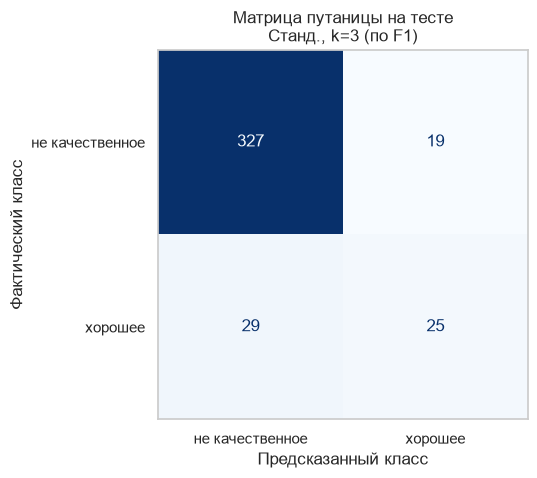

TN = 327, FP = 19, FN = 29, TP = 25
precision = TP / (TP + FP) = 25 / 44 = 0.568
recall    = TP / (TP + FN) = 25 / 54 = 0.463
accuracy  = (TP + TN) / N  = 352 / 400 = 0.880


In [15]:
main_model = fitted[MAIN]
pred_main = main_model.predict(X_test)

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_main, display_labels=['не качественное', 'хорошее'],
    cmap='Blues', colorbar=False, ax=ax)
ax.grid(False)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Фактический класс')
ax.set_title(f'Матрица путаницы на тесте\n{MAIN}')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_main).ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
print(f'precision = TP / (TP + FP) = {tp} / {tp + fp} = {tp / (tp + fp):.3f}')
print(f'recall    = TP / (TP + FN) = {tp} / {tp + fn} = {tp / (tp + fn):.3f}')
print(f'accuracy  = (TP + TN) / N  = {tp + tn} / {len(y_test)} = {(tp + tn) / len(y_test):.3f}')

In [16]:
print(classification_report(y_test, pred_main, target_names=['не качественное', 'хорошее'], digits=3))

                 precision    recall  f1-score   support

не качественное      0.919     0.945     0.932       346
        хорошее      0.568     0.463     0.510        54

       accuracy                          0.880       400
      macro avg      0.743     0.704     0.721       400
   weighted avg      0.871     0.880     0.875       400



Для сравнения — матрицы путаницы остальных вариантов с подобранным $k$.

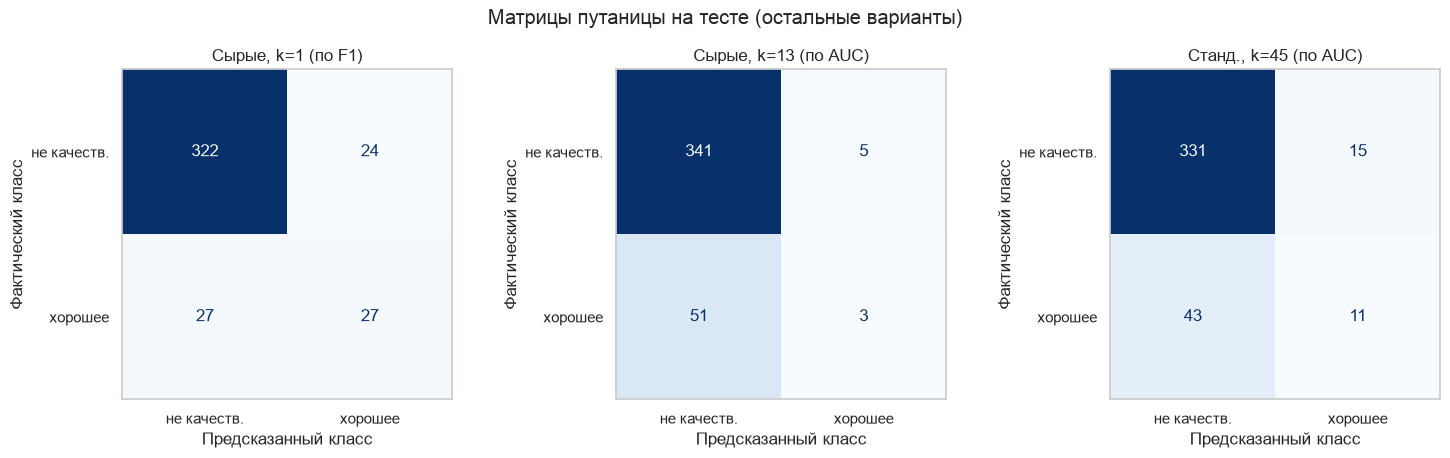

Сырые, k=1 (по F1): TN = 322, FP = 24, FN = 27, TP = 27
Сырые, k=13 (по AUC): TN = 341, FP = 5, FN = 51, TP = 3
Станд., k=45 (по AUC): TN = 331, FP = 15, FN = 43, TP = 11


In [17]:
others = [configs[1], configs[2], configs[5]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, _, _) in zip(axes, others):
    ConfusionMatrixDisplay.from_predictions(
        y_test, fitted[name].predict(X_test), display_labels=['не качеств.', 'хорошее'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.grid(False)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Фактический класс')
    ax.set_title(name)
fig.suptitle('Матрицы путаницы на тесте (остальные варианты)')
plt.tight_layout()
plt.show()

for name, _, _ in others:
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, fitted[name].predict(X_test)).ravel()
    print(f'{name}: TN = {tn_}, FP = {fp_}, FN = {fn_}, TP = {tp_}')

**Разбор главной матрицы.** Из 54 хороших вин модель нашла 25 ($TP = 25$) и пропустила 29 ($FN = 29$). Из 44 вин, названных хорошими, верно названы 25 ($\text{precision} = 25/44 = 0.568$), а 19 — ложные срабатывания ($FP = 19$). Не качественное вино модель распознаёт почти всегда: 327 из 346. Большая accuracy (0.880) в основном складывается из этих 327.

Остальные матрицы показывают, насколько результат зависит от $k$ и масштаба. Сырые признаки с $k = 1$ находят чуть больше хороших вин (27 из 54), но ценой 24 ложных срабатываний. Сырые признаки с $k = 13$ находят лишь 3 хороших вина из 54, то есть почти не отличаются от константной модели. Стандартизованные с $k = 45$ находят 11 из 54.

### 4.4. ROC-кривая и AUC

**Откуда берётся кривая.** Многие классификаторы сначала выдают числовую оценку, а класс получают сравнением с порогом $t$: $\hat{y}(x) = [\, s(x) \ge t \,]$. У kNN оценкой служит доля соседей класса «хорошее» (см. теорию), а привычное голосование — это порог $t = 0.5$. Но 0.5 — выбор по умолчанию, а не закон природы, и для редкого класса он может быть неудачным.

Если менять порог от больших значений к малым, получаются разные пары чисел:

$$\text{TPR} = \frac{TP}{TP + FN}, \qquad \text{FPR} = \frac{FP}{FP + TN}.$$

TPR — это тот же recall: доля найденных хороших вин. FPR — доля не качественных вин, ошибочно названных хорошими. Каждому порогу соответствует точка $(\text{FPR}, \text{TPR})$. **ROC-кривая** — линия через эти точки: при пороге выше всех оценок все объекты считаются не качественными, точка $(0, 0)$; при пороге ниже всех оценок все объекты считаются хорошими, точка $(1, 1)$. Чем выше и левее идёт кривая, тем лучше: хорошие вина находятся с меньшим числом ложных срабатываний.

**AUC** (Area Under Curve) — площадь под ROC-кривой, число от 0 до 1. Его вероятностный смысл: AUC равен вероятности того, что случайно выбранный положительный объект получит оценку выше, чем случайно выбранный отрицательный (при равных оценках засчитывается половина). Иначе говоря, AUC измеряет, насколько хорошо модель **упорядочивает** объекты двух классов, и не зависит от выбранного порога.

- $\text{AUC} = 1$ — положительные объекты всегда получают оценки выше отрицательных, идеальное упорядочивание;
- $\text{AUC} = 0.5$ — упорядочивание не лучше случайного, кривая совпадает с диагональю из $(0, 0)$ в $(1, 1)$; константная модель всегда получает 0.5;
- $\text{AUC} < 0.5$ — оценки упорядочивают классы в обратную сторону.

Ограничения: AUC не подсказывает, какой порог выбрать, а на небольшой выборке сильно колеблется, потому что опирается на сравнение пар. В нашей тестовой выборке хороших вин немного, так что значение AUC надо читать с оглядкой на этот разброс. Подробный разбор — в статье А. Дьяконова «AUC ROC (площадь под кривой ошибок)» (alexanderdyakonov.wordpress.com, 2017).

Проверим вероятностный смысл на нашей модели: посчитаем долю пар «хорошее — не качественное», в которых хорошее вино получило оценку выше, и сравним с `roc_auc_score`.

In [18]:
proba = main_model.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()

pos, neg = proba[y_arr == 1], proba[y_arr == 0]
diff = pos[:, None] - neg[None, :]            # все пары (хорошее, не качественное)
auc_pairs = (diff > 0).mean() + 0.5 * (diff == 0).mean()

print(f'Пар (хорошее, не качественное): {diff.size}')
print(f'Доля пар, где у хорошего вина оценка выше (ничья = 0.5): {auc_pairs:.4f}')
print(f'roc_auc_score:                                           {roc_auc_score(y_test, proba):.4f}')
print('predict совпадает с правилом «доля хороших соседей >= 0.5»:',
      bool(np.array_equal(pred_main, (proba >= 0.5).astype(int))))

Пар (хорошее, не качественное): 18684
Доля пар, где у хорошего вина оценка выше (ничья = 0.5): 0.8304
roc_auc_score:                                           0.8304
predict совпадает с правилом «доля хороших соседей >= 0.5»: True


Числа совпадают, так что AUC действительно можно читать как вероятность правильного упорядочивания случайной пары. Последняя строка подтверждает, что стандартное предсказание kNN — это порог 0.5 по доле соседей.

Посмотрим, как меняются TPR и FPR при разных порогах для двух стандартизованных моделей: с $k$ по F1 и с $k$ по AUC.

In [19]:
def rates_at(model, thresholds):
    score = model.predict_proba(X_test)[:, 1]
    out = []
    for t in thresholds:
        pred = score >= t
        out.append({'порог t': t,
                    'TPR (recall)': (pred & (y_arr == 1)).sum() / (y_arr == 1).sum(),
                    'FPR': (pred & (y_arr == 0)).sum() / (y_arr == 0).sum()})
    return pd.DataFrame(out).set_index('порог t').round(3)


thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
name_f1, name_auc = configs[4][0], configs[5][0]
pd.concat({name_f1: rates_at(fitted[name_f1], thresholds),
           name_auc: rates_at(fitted[name_auc], thresholds)}, axis=1)

Станд., k=3 (по F1)        Станд., k=45 (по AUC)       
               TPR (recall)    FPR          TPR (recall)    FPR
порог t                                                        
0.1                   0.815  0.208                 0.741  0.321
0.2                   0.815  0.208                 0.593  0.156
0.3                   0.815  0.208                 0.519  0.107
0.4                   0.463  0.055                 0.389  0.092
0.5                   0.463  0.055                 0.204  0.043
0.6                   0.463  0.055                 0.130  0.009
0.7                   0.167  0.014                 0.019  0.000

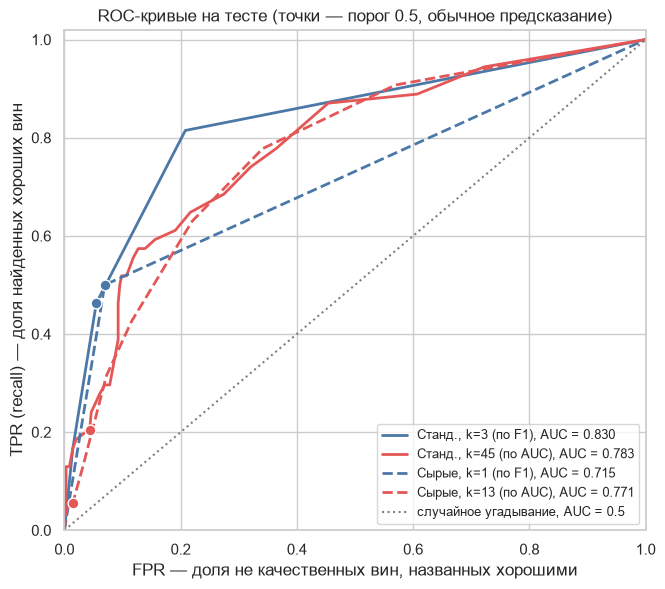

In [20]:
curves = [  # (модель, цвет, стиль линии)
    (configs[4][0], '#4C78A8', '-'),    # станд., k по F1
    (configs[5][0], '#E45756', '-'),    # станд., k по AUC
    (configs[1][0], '#4C78A8', '--'),   # сырые, k по F1
    (configs[2][0], '#E45756', '--'),   # сырые, k по AUC
]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name, color, ls in curves:
    model = fitted[name]
    score = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, color=color, ls=ls, lw=2, label=f'{name}, AUC = {roc_auc_score(y_test, score):.3f}')
    # точка, соответствующая обычному предсказанию (порог 0.5)
    pred = model.predict(X_test)
    ax.scatter([((pred == 1) & (y_arr == 0)).sum() / (y_arr == 0).sum()],
               [((pred == 1) & (y_arr == 1)).sum() / (y_arr == 1).sum()],
               color=color, s=60, zorder=3, edgecolors='white')
ax.plot([0, 1], [0, 1], color='gray', ls=':', label='случайное угадывание, AUC = 0.5')
ax.set_xlabel('FPR — доля не качественных вин, названных хорошими')
ax.set_ylabel('TPR (recall) — доля найденных хороших вин')
ax.set_title('ROC-кривые на тесте (точки — порог 0.5, обычное предсказание)')
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plt.show()

**Что показывают ROC-кривые и таблица порогов.**

- AUC на тесте: стандартизованные признаки — 0.830 ($k = 3$) и 0.783 ($k = 45$); сырые — 0.715 ($k = 1$) и 0.771 ($k = 13$). Все четыре значения заметно выше 0.5 (случайное угадывание). У главной модели AUC = 0.830: это вероятность того, что случайное хорошее вино получит оценку выше, чем случайное не качественное, причём ничья считается за ½. У $k = 3$ оценка принимает всего четыре значения, поэтому ничьих много: строго выше оценка у хорошего вина в 72.3 % пар, ничья в 21.5 %, ниже в 6.2 %; расчёт по парам дал то же число, что и `roc_auc_score`.
- У kNN с малым $k$ кривая ломаная и грубая. При $k = 3$ оценка принимает всего четыре значения (0, 1/3, 2/3, 1), поэтому пороги 0.1, 0.2 и 0.3 дают одну и ту же точку (TPR 0.815, FPR 0.208), а пороги 0.4, 0.5 и 0.6 — другую (TPR 0.463, FPR 0.055). Понижение порога с 0.5 до 1/3 поднимает долю найденных хороших вин с 0.463 до 0.815, но и доля ложных срабатываний растёт с 0.055 до 0.208. Что выгоднее — зависит от цены ошибки.
- У $k = 1$ оценка принимает только значения 0 и 1, и кривая состоит из двух отрезков (синяя пунктирная линия).
- У модели с $k = 45$ при обычном пороге 0.5 TPR всего 0.204 при FPR 0.043. При пороге 0.3 TPR вырастает до 0.519 (FPR 0.107), при 0.2 — до 0.593 (FPR 0.156). То есть оценка у этой модели упорядочивает объекты неплохо, но стандартный порог 0.5 слишком строг для класса, на который приходится 13.6 % выборки: доля хороших соседей редко превышает половину. Именно поэтому при росте $k$ F1 падает, а AUC держится. Подбор порога (например, по кросс-валидации на обучающей выборке) в этой работе не делался.

Тестовая выборка небольшая (54 хороших вина), поэтому полезно оценить, как сильно метрики могут «гулять» от случайного состава теста. Для этого перевыбираем объекты теста с возвращением (бутстрэп, 1000 повторов) и смотрим 95 % интервал по повторам. Модели при этом не переобучаются, пересчитываются только метрики.

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
names_b = [name_f1, name_auc]
scores_b = {n: fitted[n].predict_proba(X_test)[:, 1] for n in names_b}
preds_b = {n: fitted[n].predict(X_test) for n in names_b}

boot = {n: {'AUC': [], 'F1': []} for n in names_b}
auc_diff = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), size=len(y_arr))
    yt = y_arr[idx]
    for n in names_b:
        boot[n]['AUC'].append(roc_auc_score(yt, scores_b[n][idx]))
        boot[n]['F1'].append(f1_score(yt, preds_b[n][idx], zero_division=0))
    auc_diff.append(boot[names_b[0]]['AUC'][-1] - boot[names_b[1]]['AUC'][-1])


def interval(values):
    lo, hi = np.percentile(values, [2.5, 97.5])
    return f'[{lo:.3f}; {hi:.3f}]'


rows = {}
for n in names_b:
    rows[n] = {'AUC': round(roc_auc_score(y_test, scores_b[n]), 3), 'AUC, 95% интервал': interval(boot[n]['AUC']),
               'F1': round(f1_score(y_test, preds_b[n]), 3), 'F1, 95% интервал': interval(boot[n]['F1'])}
display(pd.DataFrame(rows).T)
print(f'Разность AUC ({names_b[0]} минус {names_b[1]}): '
      f'{roc_auc_score(y_test, scores_b[names_b[0]]) - roc_auc_score(y_test, scores_b[names_b[1]]):.3f}, '
      f'95% интервал {interval(auc_diff)}')

,AUC,"AUC, 95% интервал",F1,"F1, 95% интервал"
"Станд., k=3 (по F1)",0.83,[0.771; 0.885],0.51,[0.383; 0.621]
"Станд., k=45 (по AUC)",0.783,[0.711; 0.852],0.275,[0.139; 0.404]


Разность AUC (Станд., k=3 (по F1) минус Станд., k=45 (по AUC)): 0.048, 95% интервал [-0.001; 0.099]


Ещё одна проверка устойчивости. По кросс-валидации AUC выше при $k = 45$, чем при $k = 3$, а на нашем тесте наоборот (0.783 против 0.830). Чтобы понять, закономерность это или особенность одного разбиения, обучим те же две конфигурации ($k$ уже выбраны и не меняются) на 20 других случайных разбиениях train/test.

In [22]:
k_f1, k_auc = configs[4][2], configs[5][2]
rows = []
for seed in range(1, 21):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
    row = {}
    for k in (k_f1, k_auc):
        model = make_knn(k, True).fit(Xa, ya)
        row[f'AUC, k={k}'] = roc_auc_score(yb, model.predict_proba(Xb)[:, 1])
        row[f'F1, k={k}'] = f1_score(yb, model.predict(Xb), zero_division=0)
    rows.append(row)
rep = pd.DataFrame(rows)

print('Стандартизованные признаки, 20 случайных разбиений (метрики на test каждого разбиения):')
display(rep.agg(['mean', 'std', 'min', 'max']).round(3))
print(f'Доля разбиений, где AUC при k={k_auc} выше, чем при k={k_f1}: '
      f'{(rep[f"AUC, k={k_auc}"] > rep[f"AUC, k={k_f1}"]).mean():.0%}')
print(f'Доля разбиений, где F1 при k={k_auc} выше, чем при k={k_f1}: '
      f'{(rep[f"F1, k={k_auc}"] > rep[f"F1, k={k_f1}"]).mean():.0%}')

Стандартизованные признаки, 20 случайных разбиений (метрики на test каждого разбиения):


,"AUC, k=3","F1, k=3","AUC, k=45","F1, k=45"
mean,0.807,0.508,0.844,0.315
std,0.032,0.068,0.027,0.061
min,0.734,0.375,0.783,0.216
max,0.861,0.648,0.892,0.444


Доля разбиений, где AUC при k=45 выше, чем при k=3: 95%
Доля разбиений, где F1 при k=45 выше, чем при k=3: 0%


**Как читать эти проверки.**

- Бутстрэп показывает большой разброс. AUC главной модели 0.830 с 95 % интервалом [0.771; 0.885]; F1 0.510 с интервалом [0.383; 0.621]. У модели с $k = 45$ AUC 0.783 [0.711; 0.852] и F1 0.275 [0.139; 0.404]. Разность AUC между двумя моделями (0.048) имеет интервал [-0.001; 0.099], то есть на одном этом тесте их по AUC различить нельзя.
- На 20 других разбиениях картина другая: у $k = 45$ AUC в среднем выше (0.844 против 0.807) и выше в 95 % разбиений. Значит, обратный порядок на нашем тесте, по-видимому, особенность данного разбиения, а кросс-валидация, выбравшая $k = 45$ по AUC, в целом права. А вот F1 при $k = 3$ выше, чем при $k = 45$, во всех 20 разбиениях (в среднем 0.508 против 0.315).
- Итого: чем больше $k$, тем лучше модель упорядочивает объекты (AUC выходит на плато), но при обычном решающем правиле она всё хуже находит редкий класс. Какой $k$ брать, определяет цель: нужны именно ответы «хорошее / не качественное» при пороге 0.5 — подходит малый $k$; нужна оценка «степени хорошести» или готовность подобрать порог — больший.

## 5. Дополнительно: многоклассовая постановка

Теперь предсказываем саму оценку `quality` (классы 3, 4, 5, 6, 7, 8). Берём стандартизованные признаки, разбиение снова стратифицированное, но по `quality`, чтобы редкие оценки попали и в обучающую, и в тестовую часть. Значение $k$ подбираем кросс-валидацией на обучающей выборке по accuracy; macro-F1 (среднее F1 по всем классам с одинаковым весом) считаем рядом.

Число объектов по классам:
quality  3   4    5    6    7   8
train    8  40  511  478  149  13
test     2  13  170  160   50   5


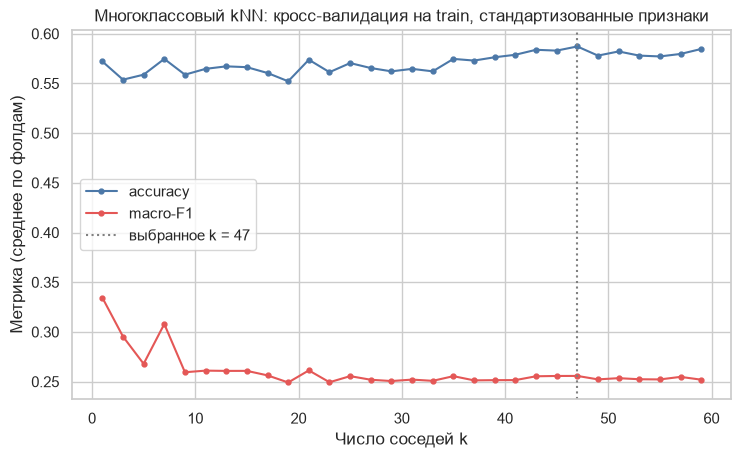

k по accuracy: 47 (accuracy = 0.587, macro-F1 = 0.256)
k по macro-F1: 1 (macro-F1 = 0.334, accuracy = 0.572)


In [23]:
y_m = df['quality']
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X, y_m, test_size=0.25, stratify=y_m, random_state=RANDOM_STATE)

print('Число объектов по классам:')
print(pd.DataFrame({'train': ym_train.value_counts().sort_index(),
                    'test': ym_test.value_counts().sort_index()}).T.to_string())

K_MULTI = list(range(1, 60, 2))
rows = []
for k in K_MULTI:
    res = cross_validate(make_knn(k, True), Xm_train, ym_train, cv=cv,
                         scoring={'acc': 'accuracy', 'mf1': 'f1_macro'})
    rows.append({'k': k, 'accuracy': res['test_acc'].mean(), 'macro-F1': res['test_mf1'].mean()})
cv_m = pd.DataFrame(rows).set_index('k')
k_multi = int(cv_m['accuracy'].idxmax())

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(cv_m.index, cv_m['accuracy'], marker='o', ms=3.5, color='#4C78A8', label='accuracy')
ax.plot(cv_m.index, cv_m['macro-F1'], marker='o', ms=3.5, color='#E45756', label='macro-F1')
ax.axvline(k_multi, color='gray', ls=':', label=f'выбранное k = {k_multi}')
ax.set_xlabel('Число соседей k')
ax.set_ylabel('Метрика (среднее по фолдам)')
ax.set_title('Многоклассовый kNN: кросс-валидация на train, стандартизованные признаки')
ax.legend()
plt.show()

print(f'k по accuracy: {k_multi} (accuracy = {cv_m.loc[k_multi, "accuracy"]:.3f}, '
      f'macro-F1 = {cv_m.loc[k_multi, "macro-F1"]:.3f})')
print(f'k по macro-F1: {int(cv_m["macro-F1"].idxmax())} (macro-F1 = {cv_m["macro-F1"].max():.3f}, '
      f'accuracy = {cv_m.loc[int(cv_m["macro-F1"].idxmax()), "accuracy"]:.3f})')

In [24]:
multi_models = {f'k={k_multi} (по accuracy)': make_knn(k_multi, True).fit(Xm_train, ym_train),
                'k=5 (лекция)': make_knn(5, True).fit(Xm_train, ym_train)}
majority = DummyClassifier(strategy='most_frequent').fit(Xm_train, ym_train)

rows = {}
for name, model in multi_models.items():
    pred = model.predict(Xm_test)
    rows[name] = {'accuracy': accuracy_score(ym_test, pred),
                  'macro-F1': f1_score(ym_test, pred, average='macro', zero_division=0),
                  'доля ответов, отличающихся от факта не более чем на 1': np.mean(np.abs(pred - ym_test.to_numpy()) <= 1)}
pred_maj = majority.predict(Xm_test)
rows['Константа «всегда 5»'] = {'accuracy': accuracy_score(ym_test, pred_maj),
                                'macro-F1': f1_score(ym_test, pred_maj, average='macro', zero_division=0),
                                'доля ответов, отличающихся от факта не более чем на 1': np.mean(np.abs(pred_maj - ym_test.to_numpy()) <= 1)}
pd.DataFrame(rows).T.round(4)

,accuracy,macro-F1,"доля ответов, отличающихся от факта не более чем на 1"
k=47 (по accuracy),0.5825,0.2671,0.9625
k=5 (лекция),0.5800,0.2887,0.9375
Константа «всегда 5»,0.4250,0.0994,0.8575


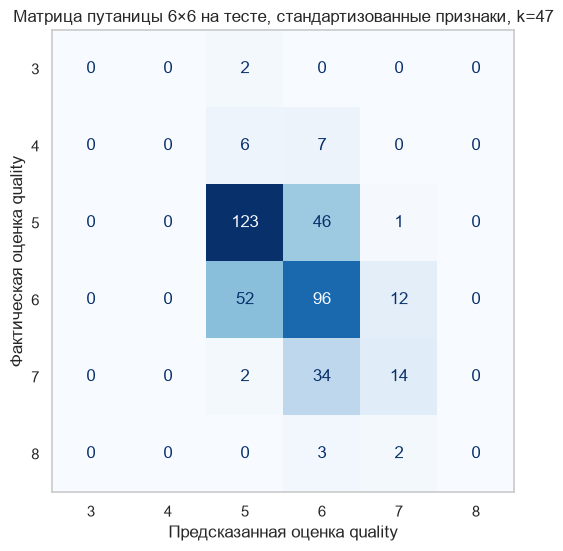

Матрица путаницы (строки — факт, столбцы — предсказание):
   3  4    5   6   7  8
3  0  0    2   0   0  0
4  0  0    6   7   0  0
5  0  0  123  46   1  0
6  0  0   52  96  12  0
7  0  0    2  34  14  0
8  0  0    0   3   2  0

              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      0.000     0.000     0.000        13
           5      0.665     0.724     0.693       170
           6      0.516     0.600     0.555       160
           7      0.483     0.280     0.354        50
           8      0.000     0.000     0.000         5

    accuracy                          0.583       400
   macro avg      0.277     0.267     0.267       400
weighted avg      0.549     0.583     0.561       400



In [25]:
main_multi = multi_models[f'k={k_multi} (по accuracy)']
pred_multi = main_multi.predict(Xm_test)
labels = list(range(3, 9))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(ym_test, pred_multi, labels=labels, cmap='Blues',
                                        colorbar=False, ax=ax)
ax.grid(False)
ax.set_xlabel('Предсказанная оценка quality')
ax.set_ylabel('Фактическая оценка quality')
ax.set_title(f'Матрица путаницы 6×6 на тесте, стандартизованные признаки, k={k_multi}')
plt.show()

print('Матрица путаницы (строки — факт, столбцы — предсказание):')
print(pd.DataFrame(confusion_matrix(ym_test, pred_multi, labels=labels), index=labels, columns=labels).to_string())
print()
print(classification_report(ym_test, pred_multi, labels=labels, zero_division=0, digits=3))

**Что получилось в многоклассовой постановке.**

- В тесте классов 3 и 8 всего 2 и 5 объектов (в обучающей выборке 8 и 13), класса 4 — 13. Это редкие классы, и модели почти нечему на них учиться.
- По кросс-валидации accuracy почти не зависит от $k$ (по выводу выше лучшее значение 0.587 при $k = 47$), а macro-F1 лучше всего при $k = 1$ (0.334) и при больших $k$ остаётся заметно ниже (на графике около 0.25): редкие классы исчезают из ответов. Выбор $k = 47$ по accuracy не слишком принципиален: кривая почти плоская (по графику значения лежат между 0.55 и 0.59).
- На тесте accuracy 0.5825 и macro-F1 0.2671. Константа «всегда 5» даёт 0.425 и 0.0994, так что kNN лучше неё по обеим метрикам, но macro-F1 остаётся низким. При $k = 5$ из лекции accuracy 0.5800, macro-F1 0.2887.
- Классы 3, 4 и 8 модель не предсказывает ни разу (соответствующие столбцы матрицы нулевые), у них precision, recall и F1 равны нулю. Больше всего вин правильно определяются в классах 5 (recall 0.724, F1 0.693) и 6 (recall 0.600, F1 0.555); у класса 7 recall 0.280.
- Accuracy здесь скрывает проблему: классы 5 и 6 составляют 330 из 400 тестовых объектов, и именно на них держится accuracy. Macro-F1 учитывает все классы поровну и поэтому оказывается намного ниже.
- Оценка качества порядковая, и ошибки в основном соседние: вина с оценкой 5 модель 46 раз называет шестёрками; шестёрки — пятёрками 52 раза и семёрками 12 раз; семёрки — шестёрками 34 раза. Доля ответов, которые отличаются от истинной оценки не более чем на 1, — 0.9625 (у константы 0.8575).

## 6. Дополнительно: решающие области kNN на плоскости

Чтобы увидеть, как $k$ меняет границу между классами, обучим kNN только на двух признаках — `alcohol` и `volatile acidity` (по корреляции с классом на обучающей выборке они впереди остальных, см. вывод ниже). Это иллюстрация, а не лучшая модель: на двух признаках из одиннадцати качество, естественно, ниже. Признаки стандартизуются внутри `Pipeline`, но оси показаны в исходных единицах. Точки — объекты обучающей выборки.

Корреляция признаков с классом «хорошее» (train), четыре сильнейших по модулю:
alcohol             0.44
volatile acidity   -0.29
citric acid         0.24
sulphates           0.20


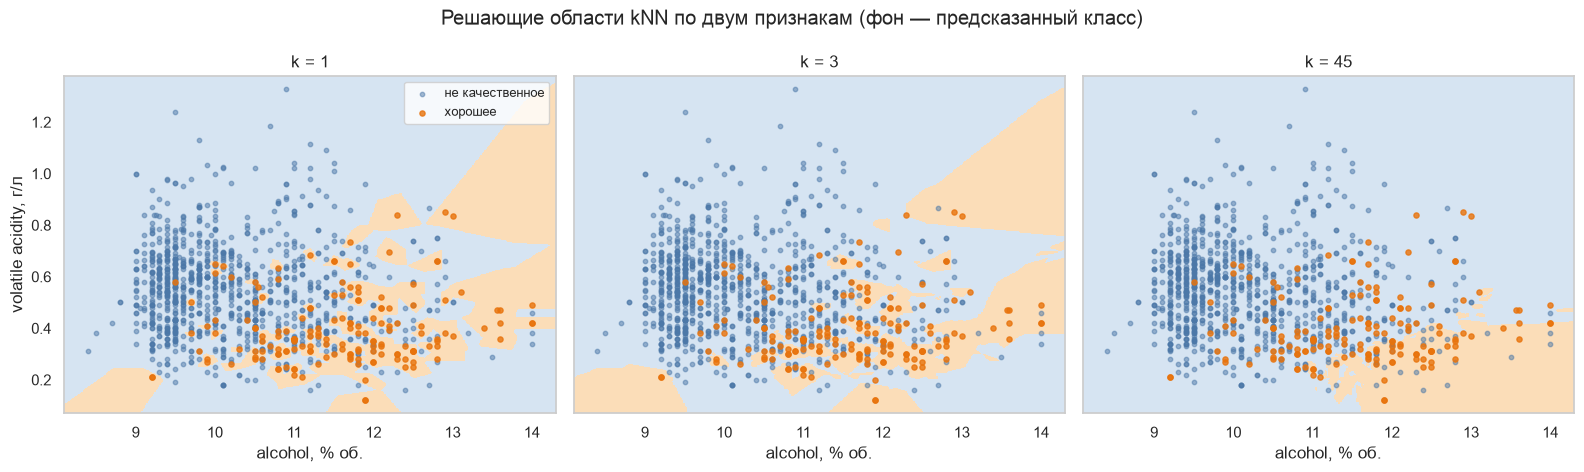

In [26]:
print('Корреляция признаков с классом «хорошее» (train), четыре сильнейших по модулю:')
print(X_train.corrwith(y_train).sort_values(key=abs, ascending=False).head(4).round(2).to_string())

two = ['alcohol', 'volatile acidity']
k_values_plot = [1, best_k[(True, 'F1')], best_k[(True, 'AUC')]]

x_min, x_max = X_train[two[0]].min() - 0.3, X_train[two[0]].max() + 0.3
y_min, y_max = X_train[two[1]].min() - 0.05, X_train[two[1]].max() + 0.05
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=two)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, k in zip(axes, k_values_plot):
    model = make_knn(k, True).fit(X_train[two], y_train)
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#D6E4F2', '#FBDDB8'])
    ax.scatter(X_train.loc[y_train == 0, two[0]], X_train.loc[y_train == 0, two[1]],
               s=10, color='#4C78A8', alpha=0.5, label='не качественное')
    ax.scatter(X_train.loc[y_train == 1, two[0]], X_train.loc[y_train == 1, two[1]],
               s=14, color='#E8730C', alpha=0.8, label='хорошее')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('alcohol, % об.')
    ax.set_title(f'k = {k}')
axes[0].set_ylabel('volatile acidity, г/л')
axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle('Решающие области kNN по двум признакам (фон — предсказанный класс)')
plt.tight_layout()
plt.show()

Видно, как $k$ управляет сложностью границы. При $k = 1$ область «хорошее» состоит из островков вокруг отдельных точек и захватывает участки, где хороших вин по одному-два: граница повторяет шум. При $k = 3$ области чуть крупнее, но всё ещё изрезаны. При $k = 45$ граница гладкая, и «хорошее» предсказывается в основном там, где высокий алкоголь сочетается с низкой летучей кислотностью. Одновременно видно, что на этих двух признаках классы сильно перекрываются: одной парой признаков качество не разделить.

## 7. Выводы

1. **Данные и постановка.** В датасете 1599 красных вин, 11 признаков, пропусков нет. Хорошее вино (`quality ≥ 7`) — 217 объектов, 13.6 %. Выборка разделена стратифицированно: 1199 объектов в обучении и 400 в тесте (54 хороших вина).

2. **Масштаб признаков.** Разброс признаков отличается в 17430 раз, и на кросс-валидации kNN на стандартизованных признаках лучше сырых при каждом проверенном $k$: лучший AUC 0.879 против 0.783, лучший F1 0.540 против 0.466. На тесте выигрыш виден по AUC (0.830 против 0.715 при $k$ по F1) и скромнее по F1 при $k = 5$ (0.387 против 0.368). При $k = 1$ сырая модель получила F1 0.514, почти как стандартизованная (0.510), но на тестовых объектах без точных копий в обучении различие по AUC заметное (0.772 против 0.591), а по F1 менее определённое (0.400 против 0.282): это нерандомное подмножество, в нём всего 37 хороших вин. Сырые признаки при больших $k$ практически не находят хорошее вино (recall 0.056 при $k = 13$).

3. **Выбор $k$.** По кросс-валидации F1 класса «хорошее» лучшее $k = 3$ (стандартизованные признаки), по AUC — $k = 45$. Эти критерии расходятся: с ростом $k$ AUC выходит на плато 0.875–0.879, а F1 падает с 0.540 до 0.305. Для главной модели взят $k = 3$ по F1; $k$ не подгонялся под тест.

4. **Главная модель на тесте** (стандартизованные признаки, $k = 3$): accuracy 0.880, precision 0.568, recall 0.463, F1 0.510, AUC 0.830. Матрица путаницы: $TN = 327$, $FP = 19$, $FN = 29$, $TP = 25$. Модель находит меньше половины хороших вин, а из тех, что назвала хорошими, правильно названы чуть больше половины. Из-за небольшого числа хороших вин в тесте оценки неточны: бутстрэп-интервал для F1 [0.383; 0.621].

5. **Accuracy и recall/F1 при дисбалансе.** Константная модель «всё не качественное» имеет accuracy 0.865, но recall и F1 равны 0. Accuracy всех рассмотренных вариантов kNN — от 0.855 до 0.880, и четыре из шести не превосходят константу. При этом F1 разных вариантов — от 0.097 до 0.514. Поэтому оценивать модель по одной accuracy нельзя: нужны precision, recall, F1 и AUC.

6. **ROC и AUC.** AUC главной модели 0.830 (случайное угадывание — 0.5); он совпал с долей правильно упорядоченных пар. AUC не зависит от порога, но и не говорит, какой порог брать. У модели с $k = 45$ AUC достаточно высок (0.783 на тесте, в среднем 0.844 на других разбиениях), а recall при обычном пороге 0.5 всего 0.204; при пороге 0.3 TPR вырастает до 0.519 (FPR 0.107). AUC на 54 хороших винах сильно «гуляет»: интервал 0.771–0.885.

7. **Многоклассовая постановка.** Accuracy 0.5825 (константа — 0.425), macro-F1 0.2671. Классы 3, 4 и 8 не предсказываются вообще; ошибки в основном соседние: 96.25 % ответов отличаются от истинной оценки не более чем на 1 (у константы — 85.75 %).

8. **Ограничения kNN.**
   - *Редкие классы.* Большое $k$ и малое число объектов редкого класса приводят к тому, что класс «тонет» среди соседей большинства: recall падает с 0.463 ($k = 3$) до 0.204 ($k = 45$), в многоклассовой задаче три класса из шести не распознаются.
   - *Цена предсказания.* Метод хранит всю обучающую выборку (1199 объектов) и для каждого нового вина считает расстояния до неё; явной модели, например уравнения разделяющей поверхности, он не даёт.
   - *Масштаб и шум.* Результат сильно зависит от масштаба признаков (см. сырые признаки) и от $k$: при $k = 1$ метод повторяет шум обучающей выборки и выигрывает от точных копий.
   - *Дубликаты.* В датасете 240 полностью повторяющихся строк, и для 94 из 400 тестовых вин в обучении есть точная копия, что завышает оценки, сильнее у сырой модели с $k = 1$ и слабее у главной.

9. **Что не делалось.** Порог решения не подбирался, признаки не отбирались, другие метрики расстояния и взвешивание соседей по расстоянию не пробовались, повторная оценка на независимых данных не проводилась; основная оценка сделана на одном разбиении (seed 0), а проверка на 20 других разбиениях проводилась только для двух стандартизованных моделей.